# Bonus B6: How to move retrieval to Pinecone

**Notebook 1 of 2: meet Pinecone on a shelf of recipe cards**

This is a bonus lab and it needs a Pinecone account; the free Starter plan is enough. Retrieval itself needs no
account: Lab 12 teaches it with Chroma, which runs inside the notebook.

## Goal

Keep vectors in Pinecone, a vector database that runs as a service in your account and not inside this notebook. We
use six recipe cards. A question about a cold, rainy night shares no word with any card and still finds the two
soups. Then we tell the search to look only at the desserts, and it returns a dessert even though no dessert suits a
cold night: the better of the two it was allowed to rank, with one of the lowest scores on the shelf. Last we delete the index, because it stays
in the account after the notebook is closed.

Notebook 2 moves the Chinook support desk's files to Pinecone and compares the result with Chroma.

## What you will learn

- How to create a Pinecone index with a schema, and read what was created.
- How to write records to the index with `upsert` (an id, a vector, a text and a label), and check that they arrived.
- How to search with a question's vector, and read the raw result before a helper wraps it.
- How a metadata filter changes which records are ranked, and why it does not change a score.
- How to delete an index and check that it is gone.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model names from `models.env`, and
takes the keys from `.env` without printing them. This lab adds two lines for `PINECONE_API_KEY`.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The keys come from the environment or .env, and are never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."
os.environ.setdefault("PINECONE_API_KEY", local.get("PINECONE_API_KEY") or "")
assert os.environ["PINECONE_API_KEY"], "Put PINECONE_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")
print("Pinecone key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes
Pinecone key found: yes


Two clients. OpenAI makes the vectors, with a 60-second limit on each request. Pinecone stores and searches them:
`Pinecone()` reads `PINECONE_API_KEY` from the environment. This notebook makes no chat call, so the model printed
above is not used; the **embedding model** is, and `models.env` names it too.

In [2]:
import time
import numpy as np
from openai import OpenAI
from pinecone import Pinecone, DenseVectorQuery

client = OpenAI(timeout=60)
pc = Pinecone()
EMBEDDING_MODEL = settings["EMBEDDING_MODEL"]
print("embedding model:", EMBEDDING_MODEL)

embedding model: text-embedding-3-small


---

## Part A: Search the recipe cards by meaning, by hand

Before we use a service, we do its job ourselves once, on something small. Here is the shelf: six recipe cards in a
dictionary. Each card has a `kind` (soup, salad or dessert) and a `text`, the line written on the card.

In [3]:
CARDS = {
    "lentil_soup":      {"kind": "soup",    "text": "Lentil soup. Red lentils, onion, cumin, lemon. One pot, 30 minutes. Serve hot."},
    "tomato_soup":      {"kind": "soup",    "text": "Tomato soup. Roast tomatoes, garlic, basil. Serve hot with toasted bread."},
    "greek_salad":      {"kind": "salad",   "text": "Greek salad. Tomato, cucumber, olives, feta. No cooking."},
    "fattoush":         {"kind": "salad",   "text": "Fattoush. Lettuce, radish, toasted pita, sumac. No cooking."},
    "mango_sorbet":     {"kind": "dessert", "text": "Mango sorbet. Mango, sugar, lime. Freeze overnight."},
    "chocolate_mousse": {"kind": "dessert", "text": "Chocolate mousse. Dark chocolate, eggs, cream. Chill for two hours."},
}

for name, card in CARDS.items():
    print(f"{name:17} {card['kind']:8} {card['text']}")

lentil_soup       soup     Lentil soup. Red lentils, onion, cumin, lemon. One pot, 30 minutes. Serve hot.
tomato_soup       soup     Tomato soup. Roast tomatoes, garlic, basil. Serve hot with toasted bread.
greek_salad       salad    Greek salad. Tomato, cucumber, olives, feta. No cooking.
fattoush          salad    Fattoush. Lettuce, radish, toasted pita, sumac. No cooking.
mango_sorbet      dessert  Mango sorbet. Mango, sugar, lime. Freeze overnight.
chocolate_mousse  dessert  Chocolate mousse. Dark chocolate, eggs, cream. Chill for two hours.


Someone comes home wet and asks: *It is raining and I am cold. What should I make for dinner?*

A person looks at the shelf and takes down a soup. A program that searches for words has a harder time. We look in
every card for the three words that say what the question is about: *raining*, *cold* and *dinner*.

In [4]:
QUESTION = "It is raining and I am cold. What should I make for dinner?"

for name, card in CARDS.items():
    print(f"{name:17}", [word for word in ["raining", "cold", "dinner"] if word in card["text"].lower()])

lentil_soup       []
tomato_soup       []
greek_salad       []
fattoush          []
mango_sorbet      []
chocolate_mousse  []


Six empty lists: no card contains any of the three words. A search by words finds nothing here, and the soups are
still the right answer.

### Turn the cards and the question into vectors

An **embedding model** reads a text and returns a list of numbers, a **vector**. Texts that are close in meaning get
vectors that point in similar directions. **Cosine similarity** measures that: 1 for the same direction, 0 for
nothing in common, so bigger is nearer. OpenAI's embedding vectors all have length 1, and for such vectors the cosine
is the **dot product**: multiply the numbers in the same position and add them up.

`input` takes a list of texts and returns one vector per text, in the same order. We send the six cards and the
question in one call.

In [5]:
names = list(CARDS)
texts = [card["text"] for card in CARDS.values()]

response = client.embeddings.create(model=EMBEDDING_MODEL, input=texts + [QUESTION])
vectors = [item.embedding for item in response.data]

D = np.array(vectors[:6])   # the six cards
q = np.array(vectors[6])    # the question
print("D:", D.shape, "| q:", q.shape)

D: (6, 1536) | q: (1536,)


- `D` has shape **(6, 1536)**: one row per card, 1,536 numbers in each row. Row `i` belongs to `names[i]`.
- `q` has **1,536** numbers: the question, from the same model. Only vectors from one model can be compared.

### Score every card

`D @ q` multiplies each row of `D` by `q`, number by number, and adds the products: six dot products, so six
cosines. `np.argsort(-scores)` gives the row positions from the highest score to the lowest.

In [6]:
scores = D @ q

for i in np.argsort(-scores):
    print(f"{scores[i]:.3f}  {names[i]:17} {CARDS[names[i]]['kind']}")

0.401  tomato_soup       soup
0.383  lentil_soup       soup
0.326  greek_salad       salad
0.284  fattoush          salad
0.211  chocolate_mousse  dessert
0.205  mango_sorbet      dessert


The two soups come first: `tomato_soup` at 0.401 and `lentil_soup` at 0.383. Then the salads, and last the two
desserts, `chocolate_mousse` at 0.211 and `mango_sorbet` at 0.205. *Raining* and *cold* are on no card. The two soups say *Serve hot*, which is close in meaning to a question about being cold, so their vectors are the nearest to the question's vector.

That is all a vector search does: compare the question's vector with every stored vector and sort.

**Why use a vector database, then?** Our whole store is the variable `D`, and it has three limits:

- It is gone when the kernel stops, and no other program can search it.
- We keep `D`, `names` and `CARDS` in the same order ourselves. If one of them is sorted on its own, every
  result points at the wrong card.
- `D @ q` compares the question with every row. That is fine for six cards and too slow for millions.

A **vector database** keeps each vector with its id, its text and its labels, finds the nearest vectors quickly, and
is there for every program that asks. Chroma is one that runs inside our Python process. **Pinecone** is one that
runs as a service: the vectors are stored on Pinecone's servers, in your account, and our code talks to them over
the network.

**Checkpoint A.** Six empty lists from the word search. `D` is (6, 1536). The two soups score highest, the two
desserts lowest.

---

## Part B: Create an index in Pinecone

An **index** is Pinecone's name for one searchable table of records (Chroma calls it a collection). The picture
shows the four calls this notebook makes to it. Follow the numbers.

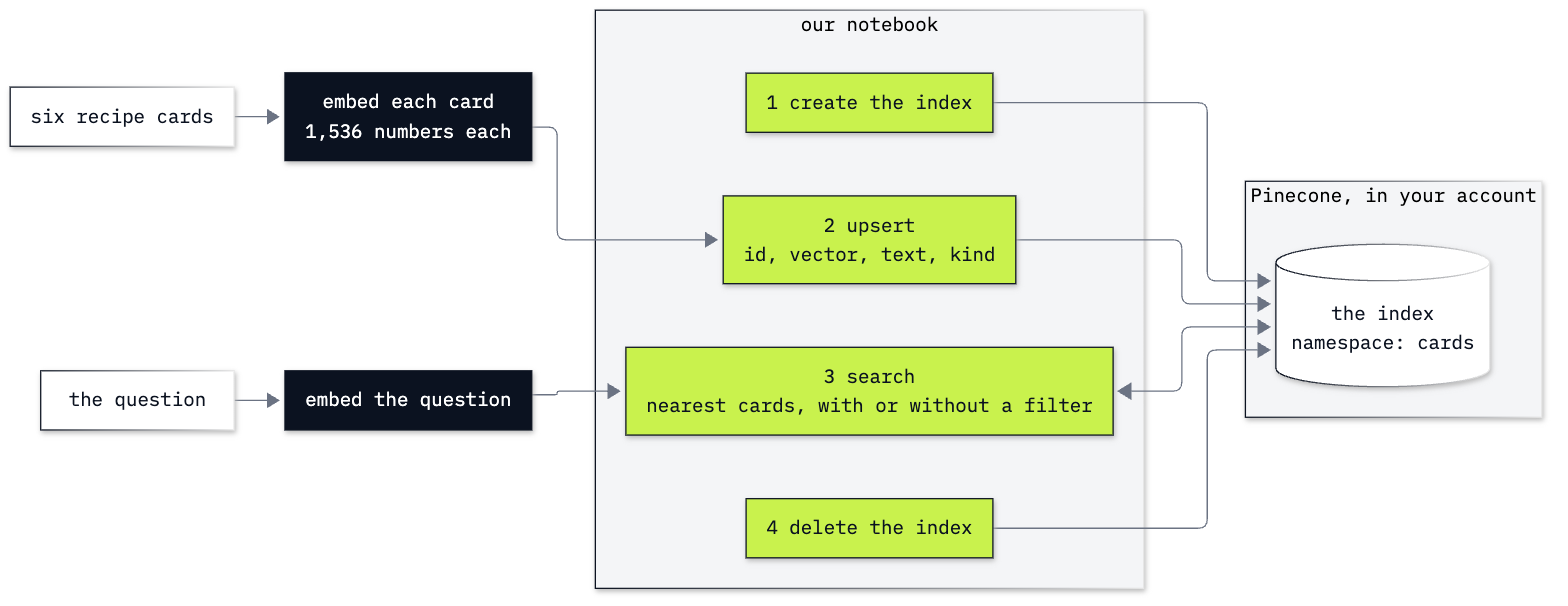

In [7]:
from IPython.display import Image

Image("resources/labB6_index_lifecycle.png", width=760)

The black boxes are calls to the embedding model. The lime boxes are the calls our code makes to Pinecone. The white
shapes are data and the index. Notice where the index is drawn: outside our notebook.

Creating an index takes three things:

| Argument | What we pass | What it means |
|---|---|---|
| `name` | `ai-agents-b6-cards` | the name the index has in your account |
| `schema` | one field, `embedding`, of type `dense_vector`, with `dimension` 1,536 and `metric` `cosine` | each record carries one vector of 1,536 numbers, and searches rank by cosine |
| `deployment` | `managed`, on `aws`, in `us-east-1` | Pinecone runs the index for us; this is the one region the free Starter plan allows |

The dimension must equal the length of our vectors, so we take it from `D.shape[1]`.

In [8]:
INDEX_NAME = "ai-agents-b6-cards"

if not pc.indexes.exists(INDEX_NAME):
    pc.indexes.create(
        name=INDEX_NAME,
        schema={"fields": {"embedding": {"type": "dense_vector", "dimension": D.shape[1], "metric": "cosine"}}},
        deployment={"deployment_type": "managed", "cloud": "aws", "region": "us-east-1"},
    )

print("exists:", pc.indexes.exists(INDEX_NAME))

exists: True


`create` returns when the index is ready to use, a few seconds later. We ask `exists` first, so running the cell a
second time does nothing: a second `create` with the same name fails with `ConflictError: [409 ALREADY_EXISTS]`.

`pc.indexes.describe` returns what Pinecone holds about the index. We print four of its fields.

In [9]:
info = pc.indexes.describe(INDEX_NAME)

print("name:      ", info.name)
print("ready:     ", info.status.ready)
print("schema:    ", info.to_dict()["schema"])
print("deployment:", info.deployment.cloud, info.deployment.region)

name:       ai-agents-b6-cards
ready:      True
schema:     {'fields': {'embedding': {'type': 'dense_vector', 'dimension': 1536, 'metric': 'cosine', 'description': None}}}
deployment: aws us-east-1


The index has our name, it is ready, and its schema is the one we sent: one dense vector field of 1,536 numbers,
ranked by cosine. (`description` is `None` because we gave the field none.) `describe` returns more than we print. One of its fields is `host`, the address our searches go
to. It is different for every project, so we do not print it.

### See the index in the console

The index now exists in your account, whether this notebook is open or not. Open the Pinecone console at
[app.pinecone.io](https://app.pinecone.io/), sign in, and find `ai-agents-b6-cards` among your project's indexes.
Check there what we printed here: the dimension 1,536 and the metric cosine. It holds no records yet.

*Screenshot to add: the Pinecone console with the index `ai-agents-b6-cards` open.*

**Checkpoint B.** `exists: True`; the name, `ready: True`, a schema with `dense_vector`, 1536 and `cosine`, and
`aws us-east-1`.

---

## Part C: Write the cards to the index with upsert

Pinecone calls a record a **document**. It is a dictionary with:

- `_id`: the record's id. We use the card's name, so every result points back to a card.
- `embedding`: the field we declared in the schema. It holds the card's vector.
- any other keys we like. We add `text` and `kind`. Pinecone stores them with the record, and we can ask for them
  back or filter on them. They are the record's **metadata**.

`D.tolist()` turns the matrix back into plain Python lists, one per card. We build the six documents and look at
the first, with its 1,536 numbers shortened to a count.

In [10]:
documents = []
for name, vector in zip(names, D.tolist()):
    documents.append({"_id": name, "embedding": vector, "text": CARDS[name]["text"], "kind": CARDS[name]["kind"]})

first = documents[0]
print({key: (f"{len(value)} numbers" if key == "embedding" else value) for key, value in first.items()})

{'_id': 'lentil_soup', 'embedding': '1536 numbers', 'text': 'Lentil soup. Red lentils, onion, cumin, lemon. One pot, 30 minutes. Serve hot.', 'kind': 'soup'}


One dictionary per card: the id, the vector, the text and the kind, together. The order of our lists no longer
matters after this, because each record carries its own id.

`pc.index(INDEX_NAME)` gives a client for this one index: `pc` creates and deletes indexes, `index` reads and writes
the records of one. **Upsert** means *update or insert*: a document with a new `_id` is added, and a document whose
`_id` already exists is replaced. So running the cell twice still leaves six records.

Every write and every search names a **namespace**, a named section inside the index. A search reads one namespace
and returns nothing from the others. We use one, `cards`; writing to it creates it.

In [11]:
index = pc.index(INDEX_NAME)

written = index.documents.upsert(namespace="cards", documents=documents)
print("upserted:", written.upserted_count)

upserted: 6


`upserted: 6` says that Pinecone accepted six documents. Pinecone applies writes in the background, and its
documentation warns that a search sent straight after a write may not see the new records yet. So before we search,
we ask the index how many records the namespace holds, and wait until it says six.

`describe_index_stats()` returns the record count of every namespace. `stored` reads one of them, and returns 0
while the namespace is not there yet.

In [12]:
def stored(namespace):
    spaces = index.describe_index_stats().namespaces
    return spaces[namespace].vector_count if namespace in spaces else 0


while stored("cards") < len(documents):
    time.sleep(1)

print("stored in cards:", stored("cards"))

stored in cards: 6


`stored in cards: 6`. In our runs the count was already 6 at the first look, so the loop never slept. Keep the loop
anyway: on a larger write, or on a busier day, the first look can come too early, and a search would then return
fewer records with no error.

`fetch` reads records back by id, with no search. We ask for one card and for two of its fields.

In [13]:
index.documents.fetch(namespace="cards", ids=["tomato_soup"], include_fields=["text", "kind"]).to_dict()

{'documents': {'tomato_soup': {'_id': 'tomato_soup',
   'kind': 'soup',
   'text': 'Tomato soup. Roast tomatoes, garlic, basil. Serve hot with toasted bread.'}},
 'namespace': 'cards',
 'usage': {'read_units': 1}}

The card came back from Pinecone's servers: its `_id`, its `text` and its `kind`, under the namespace we wrote to.
The vector is stored too; `fetch` returns only the fields named in `include_fields`. `usage` shows what the request
cost in **read units**, the unit Pinecone counts reads in.

### See the records in the console

Open the index in the console again and look at the namespace `cards`: it holds six records, with the ids we chose.

*Screenshot to add: the Pinecone console showing the six records of the namespace `cards`.*

**Checkpoint C.** The first document prints with `1536 numbers` in place of its vector; `upserted: 6`;
`stored in cards: 6`; the tomato soup card fetched by its id.

---

## Part D: Search the index with the question's vector

Pinecone holds the six vectors now. A search sends it one more vector, the question's, and asks for the nearest
records. Three arguments carry the request:

- `score_by` says what to rank by: `DenseVectorQuery` names the field to compare (`embedding`) and gives the
  question's vector as `values`.
- `top_k=3` asks for the three nearest records.
- `include_fields` names the fields to send back with each one.

We send `q`, the vector from Part A, and look at the whole result before taking it apart.

In [14]:
got = index.documents.search(
    namespace="cards",
    top_k=3,
    score_by=[DenseVectorQuery(field="embedding", values=q.tolist())],
    include_fields=["text", "kind"],
)
got.to_dict()

{'matches': [{'_id': 'tomato_soup',
   '_score': 0.4005825,
   'kind': 'soup',
   'text': 'Tomato soup. Roast tomatoes, garlic, basil. Serve hot with toasted bread.'},
  {'_id': 'lentil_soup',
   '_score': 0.3829066,
   'kind': 'soup',
   'text': 'Lentil soup. Red lentils, onion, cumin, lemon. One pot, 30 minutes. Serve hot.'},
  {'_id': 'greek_salad',
   '_score': 0.325909,
   'kind': 'salad',
   'text': 'Greek salad. Tomato, cucumber, olives, feta. No cooking.'}],
 'namespace': 'cards',
 'usage': {'read_units': 1}}

Reading the result:

- `matches` is a list, nearest first. We asked for three, so it holds three.
- Each match has `_id` (the card's name), `_score`, and the two fields we asked for.
- `_score` is the cosine, so **bigger is nearer**. (Chroma reports a distance, `1 − cosine`, where smaller is
  nearer. The order is the same.)
- `namespace` names the section that was searched, and `usage` the read units.

Compare the scores with Part A: `tomato_soup` 0.401, `lentil_soup` 0.383, `greek_salad` 0.326. They are the numbers
`D @ q` gave. **Pinecone did the same comparison we did by hand, on its servers, with the vectors we gave it.**

In Python each match has `.id` and `.score`, and our own fields by their names:

In [15]:
for match in got.matches:
    print(f"{match.score:.3f}  {match.id:17} {match.kind}")

0.401  tomato_soup       soup
0.383  lentil_soup       soup
0.326  greek_salad       salad


### `search`: a helper that takes a question in words

Every search from here on repeats two steps: embed the question, then search. Two small functions do them. `embed`
returns the vector of one text. `search` sends the same request as above and returns the same `matches`. Its
`filter` argument is passed on unchanged; `None` means no filter, and Part E uses it.

We try it on a new question: *Something sweet to cool down on a hot day*.

In [16]:
def embed(text):
    return client.embeddings.create(model=EMBEDDING_MODEL, input=text).data[0].embedding


def search(question, k=3, filter=None):
    got = index.documents.search(
        namespace="cards",
        top_k=k,
        score_by=[DenseVectorQuery(field="embedding", values=embed(question))],
        include_fields=["text", "kind"],
        filter=filter,
    )
    return got.matches


for match in search("Something sweet to cool down on a hot day"):
    print(f"{match.score:.3f}  {match.id:17} {match.kind}")

0.438  mango_sorbet      dessert
0.317  chocolate_mousse  dessert
0.304  fattoush          salad


`mango_sorbet` comes first at 0.438, well ahead of `chocolate_mousse` (0.317). The question does not say *mango*,
*sorbet* or *freeze*.

**Checkpoint D.** The raw result has `matches`, `namespace` and `usage`; the three matches are `tomato_soup`,
`lentil_soup` and `greek_salad`, with the scores of Part A; the sorbet is first for the hot-day question.

---

## Part E: Limit the search to one kind of card with a filter

Back to the rainy night. This time the person adds: *only desserts, please*. That is not a question of meaning. It
is a rule about which cards may be returned, and the `kind` we stored with every card can carry it.

A **metadata filter** tells Pinecone which records may take part in the search.
`{"kind": {"$eq": "dessert"}}` reads: the field `kind` equals `dessert`.

Before you run it: we ask for three cards. How many will come back, and with what scores?

In [17]:
for match in search(QUESTION, filter={"kind": {"$eq": "dessert"}}):
    print(f"{match.score:.3f}  {match.id:17} {match.kind}")

0.211  chocolate_mousse  dessert
0.205  mango_sorbet      dessert


Two cards, not three: the shelf has only two desserts, and the filter left nothing else to rank.
`chocolate_mousse` comes first at 0.211.

Is a chilled mousse a good dinner for someone who is cold? No. Look at all six cards for the same question, this
time from Pinecone:

In [18]:
for match in search(QUESTION, k=6):
    print(f"{match.score:.3f}  {match.id:17} {match.kind}")

0.401  tomato_soup       soup
0.383  lentil_soup       soup
0.326  greek_salad       salad
0.284  fattoush          salad
0.211  chocolate_mousse  dessert
0.205  mango_sorbet      dessert


The mousse is fifth of six, at 0.211, the same score it has in the filtered search. The sorbet is last at 0.205,
again the same.

**The filter changes which cards compete. It does not change a score.** The mousse did not become a better match
for a rainy night. It came first because the four cards above it were not allowed in.

**Important:** a filtered search still returns its best record, and nothing in the result says that the best is a
poor match. The only sign is the score, read against the scores of the other cards.

`$eq` is one of several operators. `{"kind": {"$in": ["soup", "salad"]}}` allows two kinds, and
`{"kind": {"$ne": "dessert"}}` everything but desserts.

**In production:** a filter applies a rule that a search by meaning cannot apply: a product line, a language, a date
range, or which records this user is allowed to see.

**Checkpoint E.** With the dessert filter, two cards: `chocolate_mousse` at 0.211, then `mango_sorbet` at 0.205.
In the list of six they are fifth and sixth, with the same scores.

---

## Part F: Delete the index and check that it is gone

The index is not in this notebook. If we stop here and close it, the index stays in the account with its six
records, and it counts towards the plan's limit of five indexes. So the last step of the work is to delete it.

In [19]:
pc.indexes.delete(INDEX_NAME)

print("exists:", pc.indexes.exists(INDEX_NAME))

exists: False


`delete` returns when the index is gone, a few seconds later, and `exists` now says `False`. The records went with
it, and there is no undo. Run Parts B and C again and you have the same index back: the cards are in this
notebook, and the index was only ever a copy of them.

⚠️ `pc.indexes.delete` removes the index you name, with every record in it. Delete only names you created.

**Checkpoint F.** `exists: False`. In the console, `ai-agents-b6-cards` is no longer in the list.

---

## What you can do now

- Create a Pinecone index with a one-field schema, and read its name, state and schema with `describe` (Part B).
- Write records with `upsert` as documents with an `_id`, a vector, a text and a label, check the count, and read
  one back with `fetch` (Part C).
- Search with a question's vector, read `matches`, `_id` and `_score` in the raw result, and say why the scores
  equal the ones computed by hand (Parts A and D).
- Limit a search with a metadata filter, and say why the record that comes first can still be a poor match (Part E).
- Delete an index and check that it is gone (Part F).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `AssertionError: Put PINECONE_API_KEY in .env ...` | the key is not in `.env` or in the environment | create a key in the Pinecone console, add `PINECONE_API_KEY=...` to `.env` (if your `.env` is a copy of `.env.example`, the line is already there, commented out: remove the `#` and paste the key after the `=`), and run the first cell again |
| `ConflictError: [409 ALREADY_EXISTS]` | `create` was called for a name that exists | use the cell as written: it asks `exists` first |
| an error from `search` or `upsert` after Part F (ours read `[401 UNAUTHENTICATED] Not ready`) | the index was deleted, and `index` still points at it | run Parts B and C again |
| the kernel stopped before Part F | the index is still in the account | run the first two cells, then `pc.indexes.delete("ai-agents-b6-cards")`, or delete it in the console |
| your scores differ from ours in the third decimal | the same text embedded twice can give slightly different numbers | check the order of the cards, not the last digits |

## Challenge

Two friends keep their playlists on one index, each in a namespace of their own. Here are their songs, one line each:

```python
PLAYLISTS = {
    "layla": {
        "night_bus": "A slow piano ballad about missing someone who lives far away.",
        "paper_boats": "An upbeat pop song about dancing at a summer wedding.",
        "static": "A loud rock song about quitting a boring job.",
    },
    "omar": {
        "long_road": "A quiet acoustic guitar song about heartbreak on the motorway at night.",
        "sunrise_run": "A fast electronic track for a morning workout.",
        "old_radio": "A cheerful folk tune about a grandfather's kitchen.",
    },
}
```

1. **Build the index.** Create an index named `ai-agents-b6-playlists` with the schema of Part B. Embed each
   friend's songs and upsert them into a namespace with the friend's name. Wait until each namespace holds three
   records.
2. **Search each friend's playlist.** Search *A sad song for a long drive* in `layla`, then in `omar`, with
   `top_k=1`.
3. **Search the wrong playlist.** Search *A fast track for the gym* in `layla`. What comes back, and what in the
   result tells you that Layla has no such song?
4. **Delete the index** and check that it is gone.

**Expected outcome.** 1. `exists: True`, and three records in each namespace. 2. `layla` returns `night_bus`, the piano ballad (ours 0.548), and `omar` returns `long_road`, the guitar song (0.644): the same question gets a different song from each playlist. 3. `layla` returns `static`, a loud rock song about quitting a job, at 0.235, with no error and no warning. The only sign is the score, far under the two scores of task 2; the same search in `omar` finds `sunrise_run` at 0.632. 4. `exists: False`. A worked solution is in `solved/b6a_meet_pinecone_solution.ipynb`.

## Going further

- **Let Pinecone make the vectors.** A schema can declare a text field with an embedding model. Pinecone then
  embeds the text on every write and every search, and our code sends no vectors at all. The guide is
  [integrated embedding](https://docs.pinecone.io/guides/search/integrated-embedding).
- **An older way to call Pinecone.** Many examples create an index with `dimension=` and `metric=` and then call
  `index.upsert` and `index.query`. Those calls belong to indexes without a schema. An index created with a schema,
  as here, is read and written through `index.documents`.

## Resources

- [Pinecone Python SDK: quickstart](https://sdk.pinecone.io/python/getting-started/quickstart.html): create, upsert,
  search and delete in one page, and which calls go with which kind of index.
- [Pinecone Python SDK: declare a schema and upsert documents](https://sdk.pinecone.io/python/how-to/documents/schema-and-upsert.html):
  the field types, and which fields need no place in the schema.
- [Pinecone Python SDK: search documents](https://sdk.pinecone.io/python/how-to/documents/search.html): `score_by`,
  `top_k`, `include_fields` and `filter`.
- [Pinecone: filter by metadata](https://docs.pinecone.io/guides/search/filter-by-metadata): the operators (`$eq`,
  `$ne`, `$in` and the others).
- [Pinecone: check data freshness](https://docs.pinecone.io/guides/data/check-data-freshness): why a write is not
  visible to a search at once, and how to check.
- [Pinecone Python SDK: working with namespaces](https://sdk.pinecone.io/python/how-to/vectors/namespaces.html):
  what a namespace separates.
- [Pinecone: limits by plan](https://docs.pinecone.io/reference/api/database-limits/object-limits): what the Starter
  plan allows, and its one region.
- [OpenAI: vector embeddings](https://developers.openai.com/api/docs/guides/embeddings): the embedding models and
  their sizes.